# Bài tập chương 2 — Logistic Regression
Chạy các bài theo thứ tự từ trên xuống (Run All). Mỗi bài có một cell code.

**Trên Colab:** tải `sinh_vien.csv` vào thư mục `data/` hoặc tải trực tiếp vào Files trước khi chạy. Hình bài 2 được lưu tại `figures/sigmoid.png`.


## Bài tập 1: Thống kê theo nhóm

In [1]:
from pathlib import Path
import pandas as pd

# Hỗ trợ chạy từ thư mục chương 2, code/ hoặc CSV tải trực tiếp lên Colab.
duong_dan_du_lieu = next(
    (p for p in [Path("data/sinh_vien.csv"), Path("../data/sinh_vien.csv"),
                 Path("sinh_vien.csv")] if p.is_file()), None
)
if duong_dan_du_lieu is None:
    raise FileNotFoundError("Hãy tải sinh_vien.csv lên Colab hoặc giữ thư mục data cạnh code.")
df = pd.read_csv(duong_dan_du_lieu)

nhom_diem_cao = df[df["diem_giua_ky"] >= 7]
nhom_con_lai = df[df["diem_giua_ky"] < 7]
ty_le_cao = nhom_diem_cao["qua_mon"].mean()
ty_le_con_lai = nhom_con_lai["qua_mon"].mean()

print("Số sinh viên có điểm giữa kỳ từ 7 trở lên:", len(nhom_diem_cao))
print(f"Tỷ lệ qua môn của nhóm điểm từ 7: {ty_le_cao:.4f} ({ty_le_cao:.2%})")
print(f"Tỷ lệ qua môn của nhóm còn lại: {ty_le_con_lai:.4f} ({ty_le_con_lai:.2%})")
print("Nhận xét: Nhóm có điểm giữa kỳ từ 7 có tỷ lệ qua môn cao hơn, nên điểm giữa kỳ giúp phân biệt hai nhóm trong mẫu này, nhưng không quyết định hoàn toàn việc qua môn.")


Số sinh viên có điểm giữa kỳ từ 7 trở lên: 31
Tỷ lệ qua môn của nhóm điểm từ 7: 0.9032 (90.32%)
Tỷ lệ qua môn của nhóm còn lại: 0.4831 (48.31%)
Nhận xét: Nhóm có điểm giữa kỳ từ 7 có tỷ lệ qua môn cao hơn, nên điểm giữa kỳ giúp phân biệt hai nhóm trong mẫu này, nhưng không quyết định hoàn toàn việc qua môn.


## Bài tập 2: Vẽ hàm sigmoid

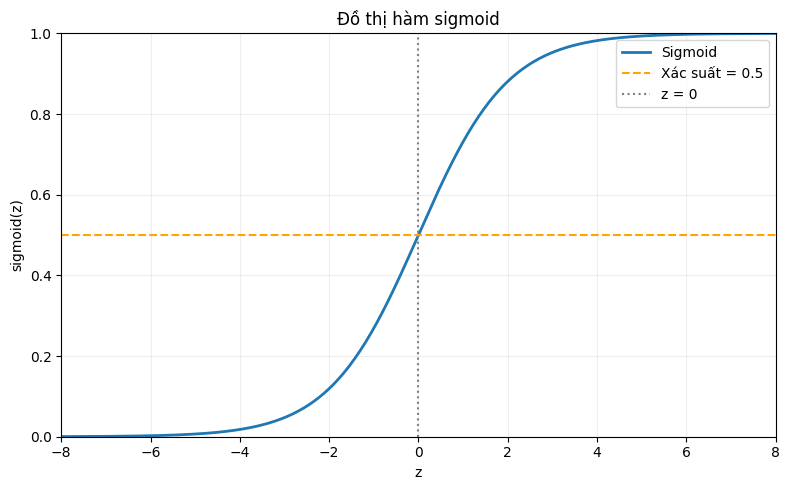

Đã lưu hình: figures/sigmoid.png


In [2]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-8, 8, 400)
xac_suat = 1 / (1 + np.exp(-z))

# Lưu hình cạnh thư mục data; trên Colab, hình nằm trong figures/.
thu_muc_du_an = (duong_dan_du_lieu.resolve().parent.parent
                 if duong_dan_du_lieu.parent.name == "data"
                 else duong_dan_du_lieu.resolve().parent)
thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(z, xac_suat, label="Sigmoid", linewidth=2)
plt.axhline(0.5, color="orange", linestyle="--", label="Xác suất = 0.5")
plt.axvline(0, color="gray", linestyle=":", label="z = 0")
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Đồ thị hàm sigmoid")
plt.xlim(-8, 8)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "sigmoid.png", dpi=150)
plt.show()
print("Đã lưu hình: figures/sigmoid.png")


## Bài tập 3: Dự đoán cho một bạn cụ thể

In [3]:
from sklearn.linear_model import LogisticRegression

# Khớp mô hình một biến trên toàn bộ dữ liệu như phần minh họa trong tài liệu.
mo_hinh_mot_bien = LogisticRegression().fit(df[["gio_on"]], df["qua_mon"])
w = float(mo_hinh_mot_bien.coef_[0][0])
b = float(mo_hinh_mot_bien.intercept_[0])

def du_doan(gio):
    """In z, xác suất qua môn và nhãn theo ngưỡng 0.5."""
    z = w * gio + b
    xac_suat = 1 / (1 + np.exp(-z))
    nhan = int(xac_suat >= 0.5)
    print(f"{gio:7.2f}   {z:9.6f}   {xac_suat:12.6f}   {nhan}")

print(f"w = {w:.6f}; b = {b:.6f}")
print("Giờ ôn      z          Xác suất qua   Nhãn")
for gio in [3, 8, 12.89, 18, 26]:
    du_doan(gio)

print(f"Giải thích: Tại giờ ôn = -b/w = {-b / w:.6f}, z = 0 nên sigmoid(z) = 0.5.")
print("12.89 là giá trị đã làm tròn của mốc này, nên xác suất chỉ gần 0.5; nhãn được tính từ xác suất chưa làm tròn.")


w = 0.392819; b = -5.064890
Giờ ôn      z          Xác suất qua   Nhãn
   3.00   -3.886432       0.020106   0
   8.00   -1.922336       0.127601   0
  12.89   -0.001451       0.499637   0
  18.00    2.005855       0.881410   1
  26.00    5.148409       0.994225   1
Giải thích: Tại giờ ôn = -b/w = 12.893693, z = 0 nên sigmoid(z) = 0.5.
12.89 là giá trị đã làm tròn của mốc này, nên xác suất chỉ gần 0.5; nhãn được tính từ xác suất chưa làm tròn.


## Bài tập 4: Tự tính bốn thước đo

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Giữ nguyên cách chia của tài liệu: 90 bạn học, 30 bạn kiểm tra.
X_train, X_test, y_train, y_test = train_test_split(
    df[["gio_on"]], df["qua_mon"],
    test_size=0.25, random_state=17, stratify=df["qua_mon"]
)
mo_hinh_kiem_tra = LogisticRegression().fit(X_train, y_train)
y_du_doan = mo_hinh_kiem_tra.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, y_du_doan, labels=[0, 1]).ravel()

# Tự tính từ bốn ô, không gọi các hàm tính thước đo của scikit-learn.
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp > 0 else 0.0
recall = tp / (tp + fn) if tp + fn > 0 else 0.0
f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn > 0 else 0.0

print(f"TN = {tn}; FP = {fp}; FN = {fn}; TP = {tp}")
print("Thước đo       Tự tính    Tài liệu")
print(f"Accuracy       {accuracy:.4f}    0.8667")
print(f"Precision      {precision:.4f}    0.8500")
print(f"Recall         {recall:.4f}    0.9444")
print(f"F1             {f1:.4f}    0.8947")
print("Nhận xét: Cả bốn kết quả tự tính đều khớp kết quả thư viện trong tài liệu khi làm tròn đến bốn chữ số thập phân.")


TN = 9; FP = 3; FN = 1; TP = 17
Thước đo       Tự tính    Tài liệu
Accuracy       0.8667    0.8667
Precision      0.8500    0.8500
Recall         0.9444    0.9444
F1             0.8947    0.8947
Nhận xét: Cả bốn kết quả tự tính đều khớp kết quả thư viện trong tài liệu khi làm tròn đến bốn chữ số thập phân.


## Bài tập 5: Dò ngưỡng tốt nhất theo F1

In [5]:
from sklearn.metrics import f1_score

# Dùng lại mô hình và tập kiểm tra ở bài 4 để chỉ thay đổi ngưỡng.
xac_suat_kiem_tra = mo_hinh_kiem_tra.predict_proba(X_test)[:, 1]
cac_nguong = np.arange(0.05, 1.0, 0.05)
cac_f1 = []

print("Ngưỡng       F1")
for nguong in cac_nguong:
    nhan_theo_nguong = (xac_suat_kiem_tra >= nguong).astype(int)
    diem_f1 = f1_score(y_test, nhan_theo_nguong, zero_division=0)
    cac_f1.append(diem_f1)
    print(f"{nguong:.2f}       {diem_f1:.4f}")

f1_cao_nhat = max(cac_f1)
# Liệt kê tất cả ngưỡng đồng hạng thay vì bỏ sót khi có nhiều đáp án.
nguong_tot_nhat = cac_nguong[np.isclose(cac_f1, f1_cao_nhat)]
print(f"F1 cao nhất: {f1_cao_nhat:.4f}")
print("Các ngưỡng tốt nhất:", ", ".join(f"{nguong:.2f}" for nguong in nguong_tot_nhat))
if np.any(np.isclose(nguong_tot_nhat, 0.5)):
    print("Nhận xét: Ngưỡng 0.5 nằm trong nhóm ngưỡng cho F1 cao nhất trên tập kiểm tra này.")
else:
    print("Nhận xét: Ngưỡng cho F1 cao nhất trên tập kiểm tra này khác 0.5.")
print("Đây là kết quả dò trên tập kiểm tra của bài tập; khi đánh giá mô hình thực tế, nên chọn ngưỡng trên tập validation rồi chấm trên tập kiểm tra riêng.")


Ngưỡng       F1
0.05       0.7826
0.10       0.8182
0.15       0.8182
0.20       0.8571
0.25       0.9000
0.30       0.8947
0.35       0.8947
0.40       0.8947
0.45       0.8947
0.50       0.8947
0.55       0.8889
0.60       0.9412
0.65       0.9412
0.70       0.9091
0.75       0.8750
0.80       0.8387
0.85       0.8000
0.90       0.5600
0.95       0.4348
F1 cao nhất: 0.9412
Các ngưỡng tốt nhất: 0.60, 0.65
Nhận xét: Ngưỡng cho F1 cao nhất trên tập kiểm tra này khác 0.5.
Đây là kết quả dò trên tập kiểm tra của bài tập; khi đánh giá mô hình thực tế, nên chọn ngưỡng trên tập validation rồi chấm trên tập kiểm tra riêng.


## Bài tập 6: Đổi lớp dương rồi chấm lại

In [6]:
from sklearn.metrics import precision_score, recall_score

# Dùng lại đúng mô hình và nhãn dự đoán mặc định ở bài 4 (ngưỡng 0.5).
# Không dùng nhãn của vòng lặp dò ngưỡng ở bài 5.
y_du_doan = mo_hinh_kiem_tra.predict(X_test)
print("Lớp dương       Precision   Recall")
for nhan_duong in [1, 0]:
    precision_lop = precision_score(y_test, y_du_doan, pos_label=nhan_duong, zero_division=0)
    recall_lop = recall_score(y_test, y_du_doan, pos_label=nhan_duong, zero_division=0)
    ten_lop = "1 (qua môn)" if nhan_duong == 1 else "0 (rớt môn)"
    print(f"{ten_lop:15s} {precision_lop:.4f}      {recall_lop:.4f}")

print("Giải thích: Đổi lớp dương làm đổi ý nghĩa đúng dương, sai dương và sai âm, dù mô hình và các dự đoán không thay đổi.")
print("Với lớp 0: precision = TN/(TN+FN) = 9/(9+1) = 0.9000; recall = TN/(TN+FP) = 9/(9+3) = 0.7500, theo các ô của ma trận khi lớp 1 là lớp dương.")
print("Với lớp 1: precision = 17/(17+3) = 0.8500; recall = 17/(17+1) = 0.9444. Hai bộ số khác nhau vì đang đánh giá hai nhóm sinh viên khác nhau.")


Lớp dương       Precision   Recall
1 (qua môn)     0.8500      0.9444
0 (rớt môn)     0.9000      0.7500
Giải thích: Đổi lớp dương làm đổi ý nghĩa đúng dương, sai dương và sai âm, dù mô hình và các dự đoán không thay đổi.
Với lớp 0: precision = TN/(TN+FN) = 9/(9+1) = 0.9000; recall = TN/(TN+FP) = 9/(9+3) = 0.7500, theo các ô của ma trận khi lớp 1 là lớp dương.
Với lớp 1: precision = 17/(17+3) = 0.8500; recall = 17/(17+1) = 0.9444. Hai bộ số khác nhau vì đang đánh giá hai nhóm sinh viên khác nhau.
